TensorFlow version: 2.21.0
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Starting GAN training...

Epoch 1/10 | Generator Loss: 0.7075 | Discriminator Loss: 1.3177


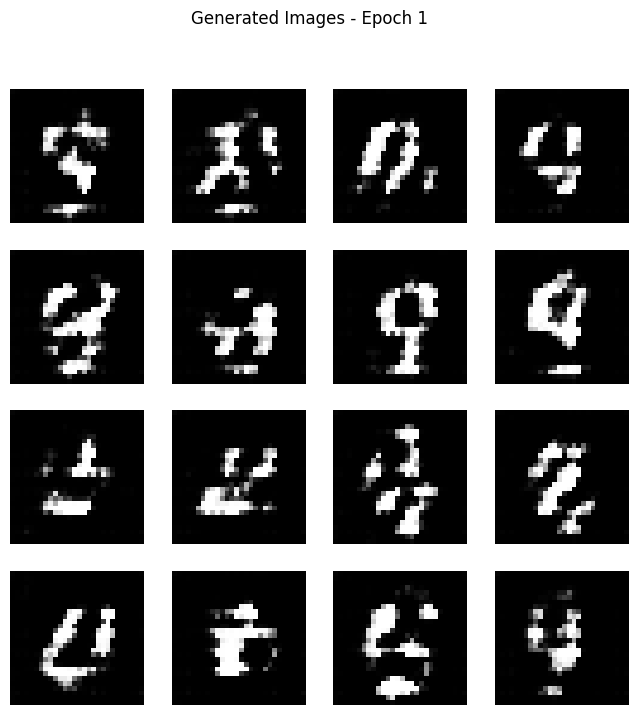

Epoch 2/10 | Generator Loss: 0.7592 | Discriminator Loss: 1.3262


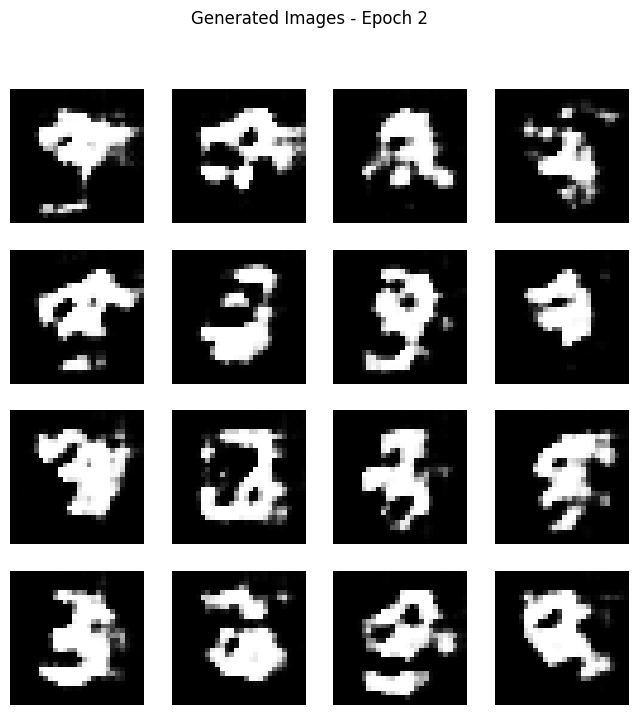

Epoch 3/10 | Generator Loss: 0.8213 | Discriminator Loss: 1.2745
Epoch 4/10 | Generator Loss: 0.8356 | Discriminator Loss: 1.2669


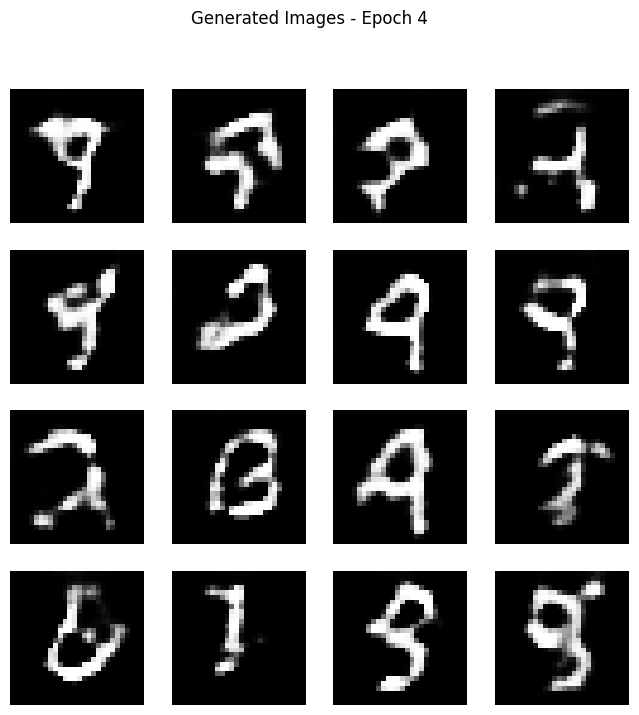

Epoch 5/10 | Generator Loss: 0.8073 | Discriminator Loss: 1.3021
Epoch 6/10 | Generator Loss: 0.7930 | Discriminator Loss: 1.3155


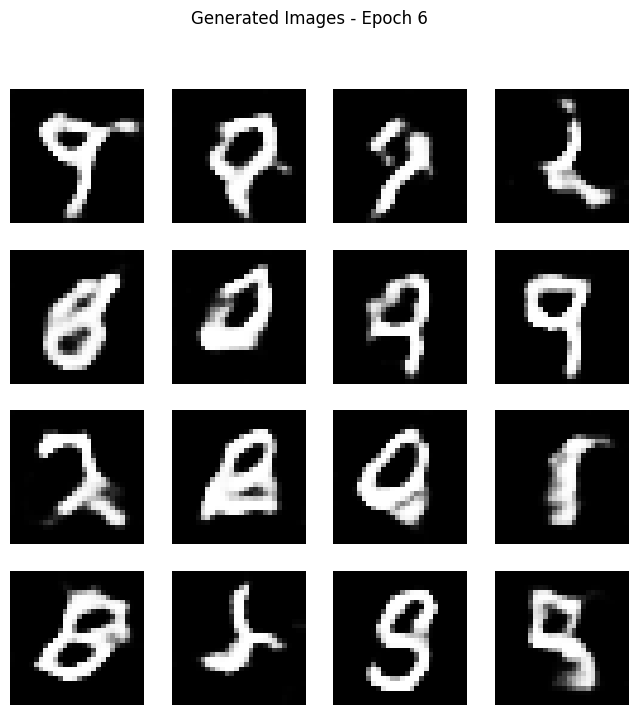

Epoch 7/10 | Generator Loss: 0.7892 | Discriminator Loss: 1.3183
Epoch 8/10 | Generator Loss: 0.7854 | Discriminator Loss: 1.3161


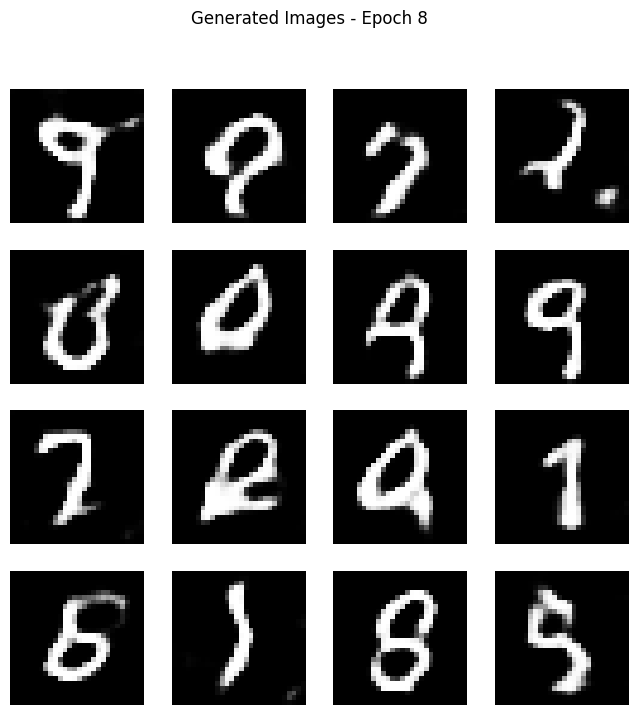

Epoch 9/10 | Generator Loss: 0.8037 | Discriminator Loss: 1.3062
Epoch 10/10 | Generator Loss: 0.7957 | Discriminator Loss: 1.3092


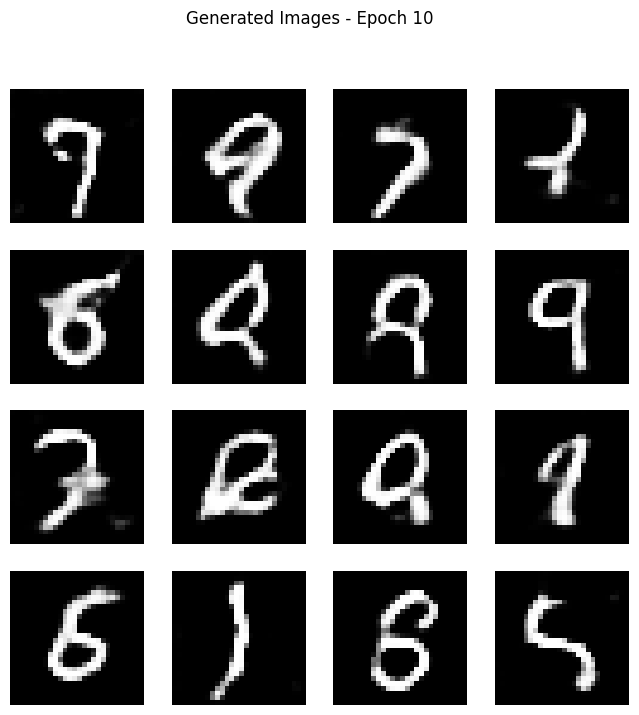


Final Generated Images


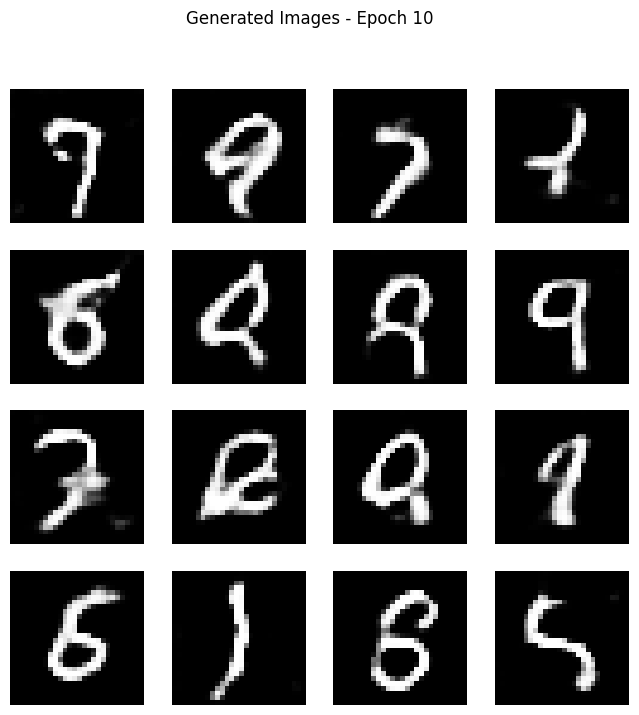

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

print("TensorFlow version:", tf.__version__)

(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

x_train = x_train.astype("float32")
x_train = (x_train - 127.5) / 127.5
x_train = np.expand_dims(x_train, axis=-1)

BUFFER_SIZE = 60000
BATCH_SIZE = 128
EPOCHS = 10
NOISE_DIM = 100

dataset = tf.data.Dataset.from_tensor_slices(x_train)
dataset = dataset.shuffle(BUFFER_SIZE).batch(BATCH_SIZE, drop_remainder=True)

def build_generator():
    model = tf.keras.Sequential([
        tf.keras.layers.Dense(7 * 7 * 256, use_bias=False, input_shape=(NOISE_DIM,)),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.LeakyReLU(),

        tf.keras.layers.Reshape((7, 7, 256)),

        tf.keras.layers.Conv2DTranspose(
            128, (5, 5), strides=(1, 1),
            padding="same", use_bias=False
        ),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.LeakyReLU(),

        tf.keras.layers.Conv2DTranspose(
            64, (5, 5), strides=(2, 2),
            padding="same", use_bias=False
        ),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.LeakyReLU(),

        tf.keras.layers.Conv2DTranspose(
            1, (5, 5), strides=(2, 2),
            padding="same", use_bias=False,
            activation="tanh"
        )
    ])

    return model

def build_discriminator():
    model = tf.keras.Sequential([
        tf.keras.layers.Conv2D(
            64, (5, 5), strides=(2, 2),
            padding="same",
            input_shape=[28, 28, 1]
        ),
        tf.keras.layers.LeakyReLU(),
        tf.keras.layers.Dropout(0.3),

        tf.keras.layers.Conv2D(
            128, (5, 5), strides=(2, 2),
            padding="same"
        ),
        tf.keras.layers.LeakyReLU(),
        tf.keras.layers.Dropout(0.3),

        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(1)
    ])

    return model

generator = build_generator()
discriminator = build_discriminator()

cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def generator_loss(fake_output):
    return cross_entropy(
        tf.ones_like(fake_output),
        fake_output
    )

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(
        tf.ones_like(real_output),
        real_output
    )

    fake_loss = cross_entropy(
        tf.zeros_like(fake_output),
        fake_output
    )

    return real_loss + fake_loss

generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

seed = tf.random.normal([16, NOISE_DIM])

@tf.function
def train_step(images):
    noise = tf.random.normal(
        [BATCH_SIZE, NOISE_DIM]
    )

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:

        generated_images = generator(
            noise,
            training=True
        )

        real_output = discriminator(
            images,
            training=True
        )

        fake_output = discriminator(
            generated_images,
            training=True
        )

        gen_loss = generator_loss(fake_output)

        disc_loss = discriminator_loss(
            real_output,
            fake_output
        )

    gradients_of_generator = gen_tape.gradient(
        gen_loss,
        generator.trainable_variables
    )

    gradients_of_discriminator = disc_tape.gradient(
        disc_loss,
        discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(
            gradients_of_generator,
            generator.trainable_variables
        )
    )

    discriminator_optimizer.apply_gradients(
        zip(
            gradients_of_discriminator,
            discriminator.trainable_variables
        )
    )

    return gen_loss, disc_loss

def generate_images(model, epoch, test_input):
    predictions = model(
        test_input,
        training=False
    )

    fig = plt.figure(figsize=(8, 8))

    for i in range(predictions.shape[0]):
        plt.subplot(4, 4, i + 1)

        plt.imshow(
            predictions[i, :, :, 0] * 0.5 + 0.5,
            cmap="gray"
        )

        plt.axis("off")

    plt.suptitle(
        "Generated Images - Epoch " + str(epoch)
    )

    plt.show()

def train(dataset, epochs):
    for epoch in range(1, epochs + 1):

        total_gen_loss = 0
        total_disc_loss = 0
        batches = 0

        for image_batch in dataset:

            gen_loss, disc_loss = train_step(
                image_batch
            )

            total_gen_loss += gen_loss
            total_disc_loss += disc_loss
            batches += 1

        avg_gen_loss = total_gen_loss / batches
        avg_disc_loss = total_disc_loss / batches

        print(
            "Epoch {}/{} | Generator Loss: {:.4f} | Discriminator Loss: {:.4f}".format(
                epoch,
                epochs,
                avg_gen_loss,
                avg_disc_loss
            )
        )

        if epoch == 1 or epoch % 2 == 0:
            generate_images(
                generator,
                epoch,
                seed
            )

print("Starting GAN training...\n")

train(
    dataset,
    EPOCHS
)

print("\nFinal Generated Images")

generate_images(
    generator,
    EPOCHS,
    seed
)